# 01 — Heterostructure electrostatics: the layer-resolved Coulomb kernel

Every quantity in this package starts from the **bare, layer-resolved Coulomb kernel**
$V_{\ell\ell'}(q,\omega)$ of $N$ two-dimensional sheets embedded in a stratified dielectric
(regions $0\dots N$, optional grounded gates). This notebook shows how to set up a geometry
with `g0w.layer_coulomb.LayerCoulomb` and checks it against closed forms.

* Poisson equation in Gaussian units, $\nabla\cdot(\varepsilon\nabla\phi)=-4\pi\rho$, uniaxial
  $\varepsilon=\mathrm{diag}(\varepsilon_\parallel,\varepsilon_\parallel,\varepsilon_z)$ in each region;
* in each region $\phi\propto e^{\pm\kappa z}$ with $\kappa=q\sqrt{\varepsilon_\parallel/\varepsilon_z}$ and admittance $Y=\varepsilon_z\kappa$;
* matching at the sheets gives a tridiagonal system $A\Phi=4\pi e\,s$ and $V(q,\omega)=4\pi e^2A^{-1}(q,\omega)$ [eV nm²].

Derivation: `docs/notes.pdf`, Sec. 2.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from g0w.layer_coulomb import LayerCoulomb, CappedLayerCoulomb, compute_kappa_Y, compute_kappa_Y_tracked
from g0w.constants import TWOPI_E2_EV_NM, E2_EV_NM
from g0w.dielectrics import HBNModel, epsilon_preset
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("e^2 =", E2_EV_NM, "eV nm")

e^2 = 1.4399764 eV nm


## 1. One sheet: open, dual-gated and single-gated

For a single sheet in a uniform medium $\varepsilon$:

| geometry | $V(q)$ |
|---|---|
| open | $2\pi e^2/(\varepsilon q)$ |
| gates at $\pm d$ | $\frac{2\pi e^2}{\varepsilon q}\tanh(qd)$ |
| one gate at $d$ | $\frac{2\pi e^2}{\varepsilon q}(1-e^{-2qd})$ |

A gate is a boundary condition $\phi=0$ that replaces the outer admittance $Y\to Y\coth(\kappa d)$.

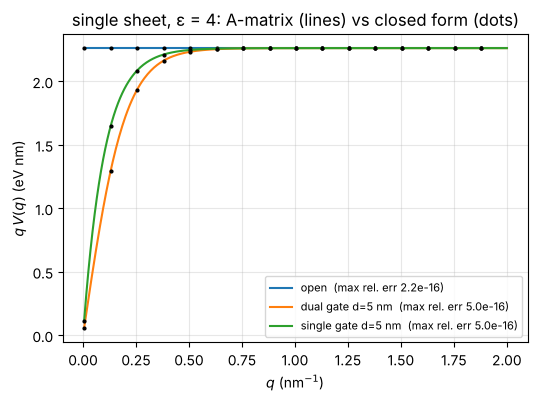

In [2]:
eps, d = 4.0, 5.0
q = np.linspace(0.005, 2.0, 400)
geoms = {
    "open": LayerCoulomb(n_layers=1, d=[], epsilon_static=[eps, eps]),
    "dual gate d=5 nm": LayerCoulomb(n_layers=1, d=[], epsilon_static=[eps, eps], top_gate_d=d, bottom_gate_d=d),
    "single gate d=5 nm": LayerCoulomb(n_layers=1, d=[], epsilon_static=[eps, eps], bottom_gate_d=d),
}
closed = {
    "open": TWOPI_E2_EV_NM / (eps * q),
    "dual gate d=5 nm": TWOPI_E2_EV_NM / (eps * q) * np.tanh(q * d),
    "single gate d=5 nm": TWOPI_E2_EV_NM / (eps * q) * (1 - np.exp(-2 * q * d)),
}
fig, ax = plt.subplots(figsize=(6, 4))
for name, lc in geoms.items():
    V = np.array([lc.coulomb_matrix(qq)[0, 0].real for qq in q])
    err = np.max(np.abs(V - closed[name]) / closed[name])
    ax.plot(q, q * V, label=f"{name}  (max rel. err {err:.1e})")
    ax.plot(q[::25], q[::25] * closed[name][::25], "k.", ms=4)
ax.set_xlabel(r"$q$ (nm$^{-1}$)"); ax.set_ylabel(r"$q\,V(q)$ (eV nm)")
ax.set_title("single sheet, ε = 4: A-matrix (lines) vs closed form (dots)")
ax.legend(fontsize=8); plt.show()

## 2. Two sheets in uniaxial hBN

Two sheets at distance $d$ in a uniform uniaxial medium: $V_{11}=V_{22}=2\pi e^2/(\bar\varepsilon q)$,
$V_{12}=V_{11}e^{-\kappa d}$, with $\bar\varepsilon=\sqrt{\varepsilon_\parallel\varepsilon_z}$ and
$\kappa=q\sqrt{\varepsilon_\parallel/\varepsilon_z}$. The **in-phase** and **out-of-phase** eigenvalues
$V_\pm=V_{11}\pm V_{12}$ drive the optical and acoustic plasmons of a bilayer.

d = 0.335 nm: V11 = 6.8774 (closed 6.8774), V12/V11 = 0.8634 (closed e^-kd = 0.8634)
d = 1.000 nm: V11 = 6.8774 (closed 6.8774), V12/V11 = 0.6450 (closed e^-kd = 0.6450)
d = 5.000 nm: V11 = 6.8774 (closed 6.8774), V12/V11 = 0.1116 (closed e^-kd = 0.1116)


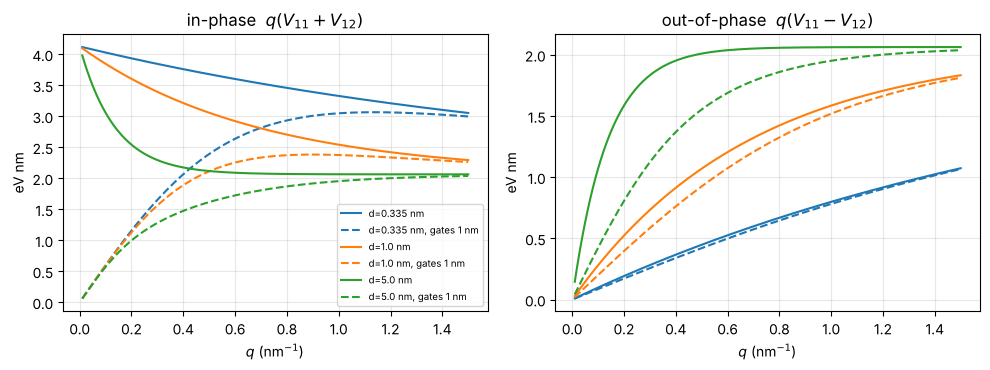

In [3]:
ep, ez = 6.41, 3.0
for d_sp in (0.335, 1.0, 5.0):
    lc = LayerCoulomb(n_layers=2, d=[d_sp], epsilon_uniaxial=([ep] * 3, [ez] * 3))
    qq = 0.3
    V = lc.coulomb_matrix(qq).real
    kap = qq * np.sqrt(ep / ez)
    print(f"d = {d_sp:5.3f} nm: V11 = {V[0,0]:.4f} (closed {TWOPI_E2_EV_NM/(np.sqrt(ep*ez)*qq):.4f}),"
          f" V12/V11 = {V[0,1]/V[0,0]:.4f} (closed e^-kd = {np.exp(-kap*d_sp):.4f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
q = np.linspace(0.01, 1.5, 300)
for d_sp, c in zip((0.335, 1.0, 5.0), ("C0", "C1", "C2")):
    for gate, ls in ((None, "-"), (1.0, "--")):
        lc = LayerCoulomb(n_layers=2, d=[d_sp], epsilon_uniaxial=([ep] * 3, [ez] * 3),
                          top_gate_d=gate, bottom_gate_d=gate)
        V = np.array([lc.coulomb_matrix(qq).real for qq in q])
        ax[0].plot(q, q * (V[:, 0, 0] + V[:, 0, 1]), ls, color=c,
                   label=f"d={d_sp} nm" + (", gates 1 nm" if gate else ""))
        ax[1].plot(q, q * (V[:, 0, 0] - V[:, 0, 1]), ls, color=c)
ax[0].set_title(r"in-phase  $q(V_{11}+V_{12})$"); ax[1].set_title(r"out-of-phase  $q(V_{11}-V_{12})$")
for a in ax: a.set_xlabel(r"$q$ (nm$^{-1}$)"); a.set_ylabel("eV nm")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

Gates suppress the long-wavelength in-phase kernel ($V_+\propto 1/q\to$ finite) but leave the
out-of-phase one ($V_-\simeq V_{11}\kappa d$) almost untouched: this is why gating raises the relative
weight of the acoustic channel (`docs/notes.pdf`, Sec. 4.4).

## 3. Dispersive hBN and passivity of V

hBN is described by one Lorentz oscillator per axis,
$\varepsilon(\omega)=\varepsilon_\infty+(\varepsilon_0-\varepsilon_\infty)/(1-\omega^2/\omega_T^2-i\gamma\omega/\omega_T^2)$.
Inside the Reststrahlen bands $\varepsilon_\parallel\varepsilon_z<0$ (hyperbolic medium) and $\kappa$ is
almost imaginary: the substrate supports phonon polaritons and $V$ acquires a large dissipative part.
For a passive medium the anti-Hermitian part of the retarded kernel must be negative semidefinite,
i.e. $-(V-V^\dagger)/2i\succeq 0$. Over a frequency sweep `compute_kappa_Y_tracked` continues
$\kappa(\omega)$ without branch jumps of the square root; for the parameters below it coincides with the
principal (decaying) branch, and both are passive.

min eigenvalue of -(V - V^+)/2i: tracked 9.85e-04, principal 9.85e-04  (>= 0: passive)
max |V_tracked - V_principal| = 0.0


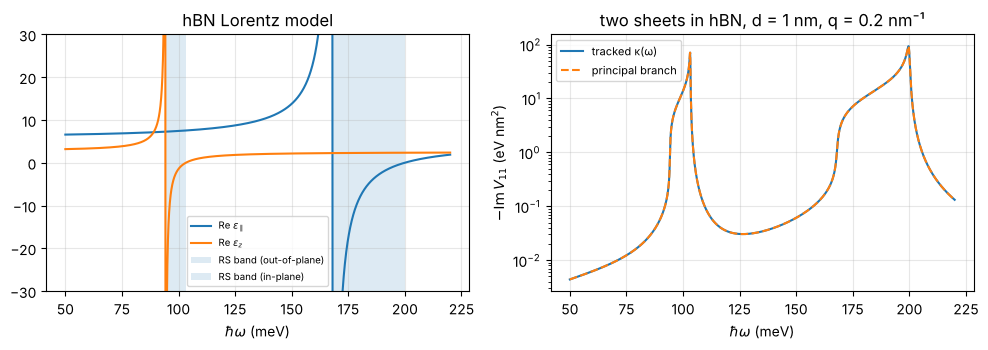

In [4]:
hbn = HBNModel()
w = np.linspace(0.05, 0.22, 2000)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(w * 1e3, hbn.eps_par(w).real, label=r"Re $\varepsilon_\parallel$")
ax[0].plot(w * 1e3, hbn.eps_z(w).real, label=r"Re $\varepsilon_z$")
for name, (a_, b_) in hbn.reststrahlen_bands().items():
    ax[0].axvspan(a_ * 1e3, b_ * 1e3, alpha=0.15, label=f"RS band ({name})")
ax[0].set_ylim(-30, 30); ax[0].set_xlabel(r"$\hbar\omega$ (meV)"); ax[0].legend(fontsize=7)
ax[0].set_title("hBN Lorentz model")

lc = LayerCoulomb(n_layers=2, d=[1.0], epsilon_dispersive=lambda r, om: (hbn.eps_par(om), hbn.eps_z(om)))
qq = 0.2
ep_w, ez_w = lc.eps_arrays_over_omega(w)
kap_t, Y_t = compute_kappa_Y_tracked(qq, ep_w, ez_w)
Vt = np.array([lc.coulomb_matrix_from_kappa_Y(qq, kap_t[:, i], Y_t[:, i]) for i in range(w.size)])
Vp = np.array([lc.coulomb_matrix(qq, om) for om in w])
ax[1].plot(w * 1e3, -Vt[:, 0, 0].imag, label="tracked κ(ω)")
ax[1].plot(w * 1e3, -Vp[:, 0, 0].imag, "--", label="principal branch")
ax[1].set_xlabel(r"$\hbar\omega$ (meV)"); ax[1].set_ylabel(r"$-\mathrm{Im}\,V_{11}$ (eV nm$^2$)")
ax[1].set_yscale("log")
ax[1].set_title(f"two sheets in hBN, d = 1 nm, q = {qq} nm⁻¹"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
def min_passivity(V):
    A = -(V - np.conj(np.swapaxes(V, 1, 2))) / 2j
    return np.linalg.eigvalsh(A).min()
print("min eigenvalue of -(V - V^+)/2i: tracked %.2e, principal %.2e  (>= 0: passive)"
      % (min_passivity(Vt), min_passivity(Vp)))
print("max |V_tracked - V_principal| =", np.max(np.abs(Vt - Vp)))

## 4. The QTM stack: SLG tip | hBN | TBG

The geometry used in notebooks 03–05: sheet 0 is the graphene tip, sheets 1–2 the two layers of
TBG separated by the 0.335 nm van der Waals gap (vacuum, $\varepsilon=1$), hBN everywhere else.
The eigenvectors of the TBG $2\times2$ block are close to $u_\pm=(1,\pm1)/\sqrt2$; the tip above one
layer breaks the symmetry slightly.

regions (eps_par, eps_z): [(6.41, 3.0), (6.41, 3.0), (1.0, 1.0), (6.41, 3.0)]


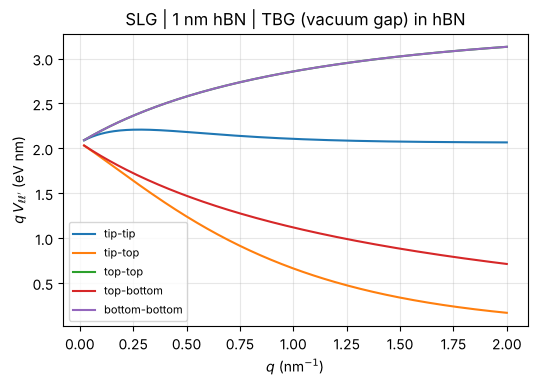

In [5]:
from g0w.models.tbg_stack import TBGSLGConfig, stack_coulomb, region_epsilon
cfg = TBGSLGConfig(d_tip=1.0)
lc3 = stack_coulomb(cfg)
print("regions (eps_par, eps_z):", list(zip(*region_epsilon(cfg))))
q = np.linspace(0.02, 2.0, 200)
V3 = np.array([lc3.coulomb_matrix(qq).real for qq in q])
fig, ax = plt.subplots(figsize=(6, 3.8))
for (i, j), lab in {(0, 0): "tip-tip", (0, 1): "tip-top", (1, 1): "top-top", (1, 2): "top-bottom", (2, 2): "bottom-bottom"}.items():
    ax.plot(q, q * V3[:, i, j], label=lab)
ax.set_xlabel(r"$q$ (nm$^{-1}$)"); ax.set_ylabel(r"$q\,V_{\ell\ell'}$ (eV nm)"); ax.legend(fontsize=8)
ax.set_title("SLG | 1 nm hBN | TBG (vacuum gap) in hBN"); plt.show()

## 5. A finite hBN flake capped by vacuum and a bottom gate

`CappedLayerCoulomb` closes region 0 with a slab of thickness $d_{\rm top}$ backed by a half-space
$\varepsilon_{\rm cap}$: $Y_{\rm eff}=Y(Y_c+Y\tanh\kappa d)/(Y+Y_c\tanh\kappa d)$, $Y_c=\varepsilon_{\rm cap}q$.

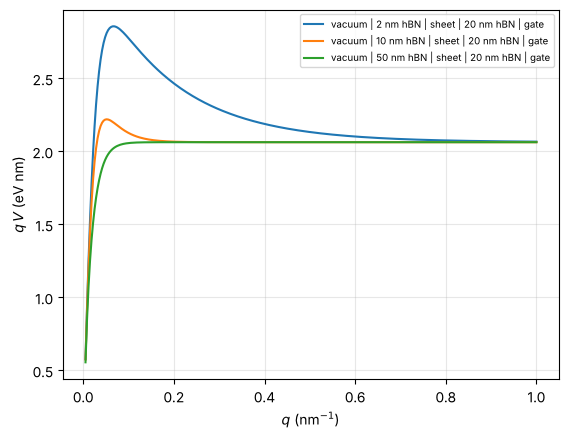

In [6]:
q = np.linspace(0.005, 1.0, 300)
for dtop in (2.0, 10.0, 50.0):
    lcc = CappedLayerCoulomb(n_layers=1, d=[], epsilon_uniaxial=([ep, ep], [ez, ez]),
                             top_slab_d=dtop, top_cap_eps=1.0, bottom_gate_d=20.0)
    V = np.array([lcc.coulomb_matrix(qq)[0, 0].real for qq in q])
    plt.plot(q, q * V, label=f"vacuum | {dtop:g} nm hBN | sheet | 20 nm hBN | gate")
plt.xlabel(r"$q$ (nm$^{-1}$)"); plt.ylabel(r"$q\,V$ (eV nm)"); plt.legend(fontsize=7); plt.show()